# 2.5 Model comparison on the 111-day window

This notebook belongs to the first part of step 2.5 of the extension, written up in `docs/report.md`, section 2.5. It compares models on the 111-day window and reads the files that `scripts/benchmark_old_window.py` writes to `results/old_window/`. A run of this notebook takes under a minute. The script takes about an hour and a half, most of it for the seasonal-decomposition model.
The 104 forecast days are split in time: the 21 last days (30 December 2020 to 19 January 2021) are the test days, the 14 days before them (16 to 29 December) are validation days, and the rest are training days. Every choice was made on the validation days. The test days were forecast once, after all choices were fixed.
Each model is refit every day on all earlier days with a published price, and then forecasts the 96 blocks of the next day. Prices are in INR/MWh. MAE is the mean absolute error and rMAE is the MAE divided by that of "same block last week".

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from rtm_forecast.metrics import daily_mae, mae, mape, summarise
from rtm_forecast.significance import bootstrap_difference, diebold_mariano

ROOT = Path("..").resolve()
FIG = ROOT / "docs" / "figures"
OUT = ROOT / "results" / "old_window"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pred = pd.read_parquet(OUT / "predictions.parquet")
test = pred[pred["period"] == "test"]
validation = pred[pred["period"] == "validation"]
print(
    "days: validation",
    validation["date"].nunique(),
    "| test",
    test["date"].nunique(),
    "| models:",
    pred["model"].nunique(),
)
print("test days:", test["date"].min().date(), "to", test["date"].max().date())

days: validation 14 | test 21 | models: 9
test days: 2020-12-30 to 2021-01-19


In [2]:
# Setting choices made on the validation days (LightGBM at fixed parameters, three seeds)
pd.read_csv(OUT / "choose_setup.csv").round(2)

,setting,inputs,MAE mean,MAE min,MAE max
0,"asinh, demand not used",18,389.39,384.40,391.89
1,"asinh, without dam_change",19,393.61,390.21,397.15
2,"asinh price, all inputs",20,395.01,394.74,395.30
3,"asinh, demand as published",20,395.14,394.09,396.96
4,"asinh, without spread_lag",19,399.64,393.32,402.81
5,"asinh, without rtm_lags",12,407.51,404.82,411.98
6,"raw price, all inputs",20,411.40,409.01,414.51
7,"asinh, without dam_today",15,423.60,417.36,427.70
8,"asinh, without calendar",17,451.83,448.31,454.89


First, which inputs to use. I compared settings with LightGBM at fixed parameters, three seeds each, on the validation days. The asinh price transform lowered the mean error from 411.40 to 395.01. Leaving the demand inputs out gave 389.39, against 395.01 with them and 395.14 with demand as published.
The seed ranges overlap, so this is a judgement: demand does not clearly help in this window, and its early values are unreliable, so I dropped it here. Removing the calendar group (which holds the block number) hurt most (451.83), then the day-ahead inputs (423.60) and the RTM lags (407.51).

In [3]:
best = json.loads((OUT / "best_params.json").read_text())
rows = []
for name, entry in best.items():
    trials = pd.read_csv(OUT / f"trials_{name}.csv")
    rows.append(
        {
            "model": name,
            "trials": len(trials),
            "validation MAE of the best trial": entry["validation_MAE"],
            "median validation MAE over trials": trials["value"].median(),
            "worst trial": trials["value"].max(),
        }
    )
print(pd.DataFrame(rows).round(2).to_string(index=False))
for name, entry in best.items():
    print(
        name, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in entry["params"].items()}
    )

   model  trials  validation MAE of the best trial  median validation MAE over trials  worst trial
lightgbm      30                            377.40                             383.72       411.92
catboost      30                            373.29                             383.33       421.89
    lear      30                            401.02                             402.40       750.26
lightgbm {'n_estimators': 175, 'learning_rate': 0.0444, 'num_leaves': 15, 'min_child_samples': 40, 'subsample': 0.6729, 'subsample_freq': 1, 'colsample_bytree': 0.722, 'reg_lambda': 0.1457, 'objective': 'huber'}
catboost {'iterations': 349, 'learning_rate': 0.0858, 'depth': 3, 'l2_leaf_reg': 1.0364, 'loss_function': 'MAE'}
lear {'alpha': 0.0001}


Each tuned model got 30 Optuna trials on the validation days (LightGBM, CatBoost, and the lasso model with its penalty). The best trial scored 377.40 (LightGBM), 373.29 (CatBoost) and 401.02 (lasso). The median trial of the two tree models scored 383.72 and 383.33, so the search gained about 6 to 10 over a typical setting.
The lasso model's best penalty (0.0001) is tiny, which means almost no shrinkage.

In [4]:
# Validation days: the models were tuned on these days, so these scores are optimistic
summarise(validation).round(3)

,MAE,RMSE,MAPE,sMAPE,rMAE
catboost,385.502,607.620,11.412,11.350,0.637
lightgbm,389.491,600.544,11.666,11.385,0.643
phase1_random_forest,400.394,621.863,11.920,11.645,0.661
phase1_xgboost,403.285,617.734,12.258,11.833,0.666
lear,404.234,599.602,12.524,12.159,0.668
dam_price,430.724,659.606,13.111,12.920,0.711
mstl_ets,455.573,683.903,14.140,13.637,0.752
naive_yesterday,491.909,791.906,14.841,14.347,0.812
naive_lastweek,605.543,942.480,17.802,18.420,1.000


These are the validation days. The models were tuned on them, so these scores are optimistic and I do not use them to rank the models.

In [5]:
# Test days: used once, after every choice was made
table = summarise(test)
table["vs Phase 1 RandomForest (%)"] = (
    table["MAE"] / table.loc["phase1_random_forest", "MAE"] - 1
) * 100
table.round(3)

,MAE,RMSE,MAPE,sMAPE,rMAE,vs Phase 1 RandomForest (%)
lear,412.428,644.937,15.581,13.614,0.674,-2.680
catboost,418.204,674.081,15.142,13.666,0.683,-1.317
phase1_random_forest,423.787,655.068,15.997,13.826,0.692,0.000
phase1_xgboost,434.598,669.631,16.305,14.198,0.710,2.551
lightgbm,434.781,662.764,16.211,14.370,0.710,2.594
dam_price,499.083,725.329,18.580,16.136,0.815,17.767
naive_yesterday,522.090,818.421,19.199,17.699,0.853,23.196
mstl_ets,581.738,837.527,19.666,19.120,0.950,37.271
naive_lastweek,612.131,956.706,21.580,20.241,1.000,44.443


On the 21 test days the lasso model (LEAR) has the lowest error (MAE 412.43, rMAE 0.674), followed by CatBoost (418.20), my first notebook's RandomForest refit under this protocol (423.79), its XGBoost (434.60) and LightGBM (434.78). The simple forecasts are far behind: the DAM price 499.08, yesterday's price 522.09, last week's price 612.13. The seasonal-decomposition model scores 581.74.
The ranking of the top models changed between the validation and test days: LightGBM went from second to fifth and LEAR from fifth to first. Tuning on 14 days did not carry over, so I treat the top five as roughly equal. The best model is only 2.68 percent below my first RandomForest.

,lear,catboost,phase1_random_forest,phase1_xgboost,lightgbm,dam_price,naive_yesterday,mstl_ets,naive_lastweek
lear,NaN,0.338,0.238,0.063,0.056,0.002,0.002,0.000,0.001
catboost,0.662,NaN,0.303,0.102,0.032,0.008,0.004,0.000,0.001
phase1_random_forest,0.762,0.697,NaN,0.061,0.139,0.004,0.003,0.000,0.001
phase1_xgboost,0.937,0.898,0.939,NaN,0.494,0.010,0.006,0.000,0.002
lightgbm,0.944,0.968,0.861,0.506,NaN,0.014,0.006,0.000,0.002
dam_price,0.998,0.992,0.996,0.990,0.986,NaN,0.278,0.011,0.037
naive_yesterday,0.998,0.996,0.997,0.994,0.994,0.722,NaN,0.073,0.093
mstl_ets,1.000,1.000,1.000,1.000,1.000,0.989,0.927,NaN,0.315
naive_lastweek,0.999,0.999,0.999,0.998,0.998,0.963,0.907,0.685,NaN


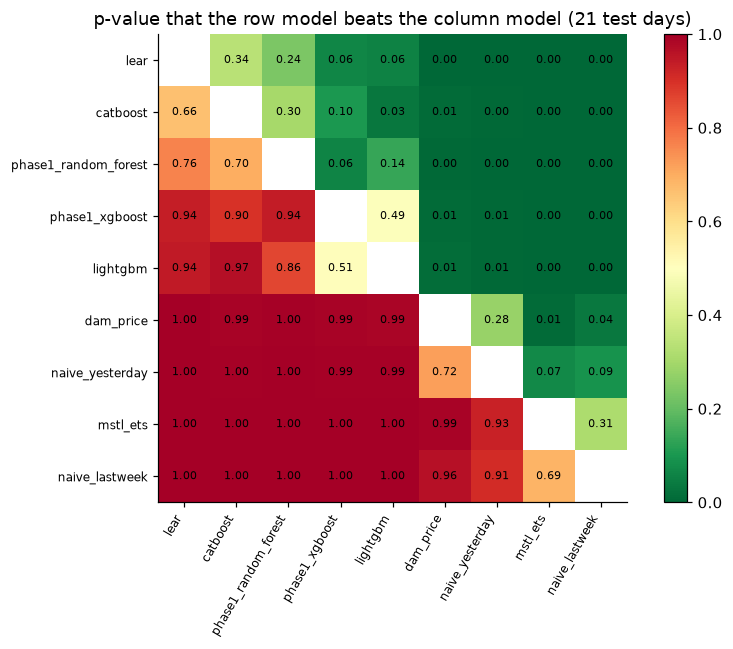

In [6]:
# One-sided Diebold-Mariano tests on the daily mean absolute error. Row model has lower loss than column model when p is small.
daily = daily_mae(test)
order = list(table.index)
pvalues = pd.DataFrame(index=order, columns=order, dtype=float)
for a in order:
    for b in order:
        if a != b:
            pvalues.loc[a, b] = diebold_mariano(daily[a].to_numpy(), daily[b].to_numpy())[1]
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(pvalues.astype(float).to_numpy(), cmap="RdYlGn_r", vmin=0, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax.text(j, i, f"{pvalues.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("p-value that the row model beats the column model (21 test days)")
ax.grid(False)
fig.colorbar(image)
fig.tight_layout()
fig.savefig(FIG / "05_dm_matrix.png")
pvalues.round(3)

No learning model is clearly better than another. Among the five, the smallest p-values are CatBoost against LightGBM (0.03), LEAR against LightGBM (0.06) and LEAR against XGBoost (0.06). With 36 pairs compared, a single p of 0.03 is weak evidence.
Every one of the five does beat the DAM price (p from 0.002 to 0.014), yesterday's price and last week's price.

In [7]:
# The three best models and the two Phase 1 models against the best simple forecast
simple = min(["naive_yesterday", "naive_lastweek", "dam_price"], key=lambda m: table.loc[m, "MAE"])
print("best simple forecast on the test days:", simple)
rows = []
for model in ["lear", "catboost", "lightgbm", "phase1_random_forest", "phase1_xgboost"]:
    stat, p = diebold_mariano(daily[model].to_numpy(), daily[simple].to_numpy())
    low, high = bootstrap_difference(daily[model].to_numpy(), daily[simple].to_numpy())
    rows.append(
        {
            "model": model,
            "mean daily MAE difference": float((daily[model] - daily[simple]).mean()),
            "95% interval low": low,
            "95% interval high": high,
            "DM p-value": p,
            "days better": int((daily[model] < daily[simple]).sum()),
        }
    )
pd.DataFrame(rows).set_index("model").round(3)

best simple forecast on the test days: dam_price


,mean daily MAE difference,95% interval low,95% interval high,DM p-value,days better
model,,,,,
lear,-86.776,-135.717,-35.881,0.002,15
catboost,-80.997,-136.580,-20.713,0.008,14
lightgbm,-64.385,-112.876,-11.004,0.014,16
phase1_random_forest,-75.352,-120.434,-24.552,0.004,16
phase1_xgboost,-64.562,-109.442,-15.622,0.010,16


Against the best simple forecast, the DAM price, the five learning models are better by 64 to 87 INR/MWh in mean daily error (LEAR -86.8, CatBoost -81.0, RandomForest -75.4, XGBoost -64.6, LightGBM -64.4). The 95 percent intervals exclude zero, and each model is better on 14 to 16 of the 21 days.
The test I set before tuning was that a model must beat the best simple forecast and both of my first notebook's models with p below 0.05. **No model meets it on this window.** The best, LEAR, beats the first RandomForest with p = 0.24 and the first XGBoost with p = 0.06.

model        lear  catboost  phase1_random_forest  dam_price  naive_yesterday
date                                                                         
2021-01-14  405.0     412.0                 481.0      613.0            495.0
2021-01-15  291.0     299.0                 311.0      443.0            459.0
2021-01-16  500.0     465.0                 415.0      438.0            454.0
2021-01-17  418.0     384.0                 319.0      404.0            377.0
2021-01-18  767.0     858.0                 823.0      575.0           1046.0
2021-01-19  480.0     709.0                 676.0      597.0            432.0


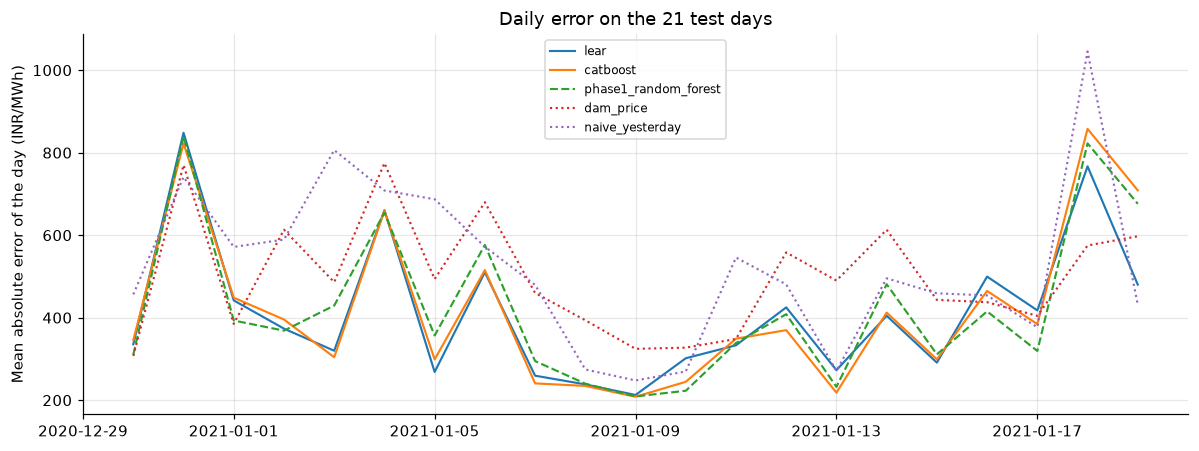

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for model, style in [
    ("lear", "-"),
    ("catboost", "-"),
    ("phase1_random_forest", "--"),
    ("dam_price", ":"),
    ("naive_yesterday", ":"),
]:
    ax.plot(daily.index, daily[model], style, label=model, lw=1.4)
ax.set_ylabel("Mean absolute error of the day (INR/MWh)")
ax.set_title("Daily error on the 21 test days")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_daily_error.png")
print(
    daily.loc[:, ["lear", "catboost", "phase1_random_forest", "dam_price", "naive_yesterday"]]
    .round(0)
    .tail(6)
    .to_string()
)

All models move together from day to day. Two days stand out in the figure, 31 December and 18 January. On 18 January the DAM price (575) beats the three models listed (767 to 858), and on that day yesterday's price is far worse (1046).

In [9]:
# Where in the day do the errors fall? Mean absolute error by six-hour window of the day.
window = pd.cut(test["block"], [0, 24, 48, 72, 96], labels=["00-06", "06-12", "12-18", "18-24"])
t = test.assign(window=window, error=(test["actual"] - test["prediction"]).abs())
by_window = t.pivot_table(
    index="window", columns="model", values="error", aggfunc="mean", observed=True
)
by_window[
    ["lear", "catboost", "lightgbm", "phase1_random_forest", "dam_price", "naive_yesterday"]
].round(0)

model,lear,catboost,lightgbm,phase1_random_forest,dam_price,naive_yesterday
window,,,,,,
00-06,258.0,242.0,272.0,261.0,299.0,327.0
06-12,594.0,618.0,614.0,631.0,806.0,729.0
12-18,401.0,430.0,456.0,413.0,427.0,497.0
18-24,397.0,382.0,398.0,390.0,464.0,535.0


Every model is worst between 06:00 and 12:00 (LEAR 594, CatBoost 618, LightGBM 614). The DAM price is much worse than the models there (806). In the afternoon the DAM price (427) is about as good as the models (LEAR 401).

In [10]:
# The original test day, 19 January 2021, under this protocol (models refit on all earlier days)
day = test[test["date"] == "2021-01-19"]
rows = {}
for model, part in day.groupby("model"):
    rows[model] = {
        "MAE": mae(part["actual"].to_numpy(), part["prediction"].to_numpy()),
        "MAPE": mape(part["actual"].to_numpy(), part["prediction"].to_numpy()),
    }
pd.DataFrame(rows).T.sort_values("MAE").round(2)

,MAE,MAPE
naive_yesterday,431.57,10.98
lear,480.16,10.64
mstl_ets,515.17,12.38
dam_price,597.38,15.89
phase1_xgboost,640.53,14.07
lightgbm,657.68,14.36
phase1_random_forest,676.10,14.67
catboost,708.76,14.96
naive_lastweek,1088.43,21.83


This is the day my first notebook used as its single test day. Under this protocol no model beats yesterday's price on MAE (431.57). LEAR is the closest (480.16) and has a slightly lower MAPE (10.64 against 10.98). The other models have MAEs from 640.53 to 708.76. It is also the hardest day of the window (step 2.2), so I do not read much into it.

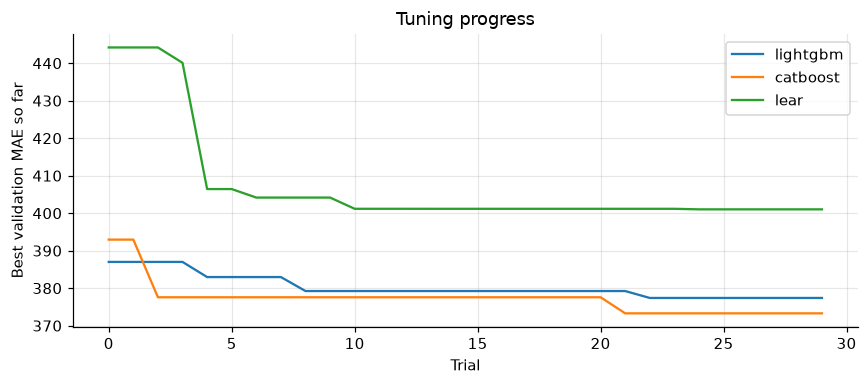

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for name in best:
    trials = pd.read_csv(OUT / f"trials_{name}.csv").sort_values("number")
    ax.plot(trials["number"], trials["value"].cummin(), label=name)
ax.set_xlabel("Trial")
ax.set_ylabel("Best validation MAE so far")
ax.set_title("Tuning progress")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "05_tuning.png")

**What I understand.** The learning models are about 17 percent better than the DAM price (LEAR 412.43 against 499.08), and that gain is real. They cannot be separated from each other on 21 days, and my first notebook's RandomForest, refit daily on corrected inputs, is within 3 percent of the best.
So the progress over my first notebook comes mostly from evaluating properly, fixing the dates and filling gaps better, not from a more complicated model. That a plain lasso model does as well as the boosted trees suggests that, once the day-ahead price and volumes are known, the relationship is simple.
The mismatch between validation and test rankings is a warning against reading a ranking from a short period. Step 2.5 continues with a year of newer data, which gives a longer test period, and with neural and pretrained models.